# Eccentric CW sky localisation — Fisher scaffold

Kernel: **aaron-fisher (JAX GPU)**. Run top to bottom from this folder (`aaron/`).
Section 1 runs as is. Sections 2–3 stop with `NotImplementedError` until you write the three stubs in `ecc_utils.py`.

**Read these first** (Steve's code, one level up — import, don't copy):

| what | where |
|---|---|
| `PulsarBatch` — TOAs, errors `(N_psr, N_toa)`, `pos` `(N_psr, 3)`, `pdist` = [mean, σ] kpc | `utils_vectorized_fixed.py` L25 |
| `get_delay_batch` — circular residuals; param order; orbital phase = `phase0/2`, ω₀ = π f_GW | `utils_vectorized_fixed.py` L146 |
| `computer_snr2_batch` — SNR² (sic, "computer") | `utils_vectorized_fixed.py` L253 |
| `compute_total_fisher` — JᵀJ/σ² by `jacrev`; `jacfwd` twin `compute_total_fisher_fwd` | `utils_vectorized_fixed.py` L266; `utils_referee.py` L162 |
| SNR = 10 calibration — rescale `log10_dist` by SNR/10 on the linked pulsar-term SNR; unit prior on normalised distances | `utils_referee.calibrated_fisher`, L180 (lines 197–201) |
| Schur-complement marginalisation — `compute_sky_area_schur`; paper figures use full-inverse `compute_sky_area` (they agree to ~cond × 1e-16: 1e-10 to 1e-6 here) | `utils_referee.py` L72, L57 |
| linked/decoupled switch — static `phase_free` in `get_delay_batch` (branch L222); fiducial free phases from `compute_pulsar_phases_batch` (L300) | `utils_vectorized_fixed.py` |

**References**
- Peters 1964, Phys. Rev. 136, B1224 — da/dt, de/dt; the a(e) relation.
- Peters & Mathews 1963, Phys. Rev. 131, 435 — harmonic power of eccentric binaries.
- Taylor et al. 2016, arXiv:1505.06208 — §2 orbit + Peters equations (eqs. 4–8); §4 eqs. (21)–(22) **eccentric residual harmonics: the ones to code**. No periastron precession: §4 (after eq. 26, Fig. 5) argues γ̇ is negligible over ~10 yr, and the §7.1 pulsar-term test evolves only F and e (eq. 6), stating "No pericenter-direction evolution … is considered". We add the 1PN ω̇ ourselves.
- Barack & Cutler 2004, PRD 69, 082005 — strain harmonics h₊,ₓ (Taylor+2016 §3 eqs. 10–11); for cross-reading only.
- Taylor 2026, arXiv:2603.10120 — the circular pulsar-term paper this extends (Section 1).
- GWecc.jl (Susobhanan+2020, arXiv:2002.03285) — numerical cross-check; models precessing (ω̇) orbits.

In [1]:
import os, sys, time
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")   # else a second JAX kernel on the GPU fails with cuSolver errors
sys.path.insert(0, "..")                      # Steve's modules live one level up
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import constants as const
import utils_vectorized_fixed as uvf
import utils_referee as urf
import ecc_utils as eu
print(jax.devices(), jnp.ones(1).dtype)

[CudaDevice(id=0)] float64


## Section 1 — Reproduce Studies 1, 3, 4

**What this does:** a ring of `N_PSR` pulsars at radius ξ around the source; amplitude rescaled so the total SNR equals `SNR_TARGET`; Fisher matrix → sky area ΔΩ marginalised over everything else. All Steve's code (`eu.ring_dOmega` wraps `urf.calibrated_fisher` + `urf.compute_sky_area`).

**Your task:** run it. Then change each knob below, one at a time, rerun, and write one sentence on what happened.

| knob | what happened |
|---|---|
| `N_PSR` | |
| `RING_RADIUS` | |
| `L0` | |
| `SIGMA_L` | |
| `LOG10_MC` | |
| `LOG10_FGW` | |
| `TOBS_YR` | |
| `CADENCE_D` | |
| `SIGMA_WN` | |
| `SNR_TARGET` | |
| `TREF_YR` | |

**How you'll know it's right:** at default knobs the figures match Steve's (links at the end of this section), Study 3 prints max ΔΩ_D/ΔΩ_L = 5.12e6 and Study 4 prints ΔΩ(10°)/ΔΩ(50°) = 23.79.

In [2]:
# ---- knobs (paper defaults) ----
N_PSR       = 20                # pulsars in the ring
RING_RADIUS = 10.0              # xi [deg]: Study 4 (with 50 deg) and Sections 2-3
L0          = 1.0               # mean pulsar distance [kpc]
SIGMA_L     = 1e-3              # pulsar-distance uncertainty [kpc], Study 3 (~1 lambda_GW)
LOG10_MC    = 9.5               # chirp mass [Msun]
LOG10_FGW   = -8.0              # GW frequency [Hz]
TOBS_YR     = 10.0              # data span [yr]
CADENCE_D   = 10 * 365.25 / 99  # TOA spacing [d] (paper: 100 TOAs over 10 yr)
SIGMA_WN    = 1e-7              # white-noise rms [s]
SNR_TARGET  = 10.0
TREF_YR     = 0.0               # tref - first TOA [yr]

T0      = 58000.0 * 86400.0
N_TOA   = int(round(TOBS_YR * 365.25 / CADENCE_D)) + 1
TOAS    = jnp.linspace(T0, T0 + (N_TOA - 1) * CADENCE_D * 86400.0, N_TOA)
TOAERRS = jnp.full_like(TOAS, SIGMA_WN)
TREF    = T0 + TREF_YR * const.yr
# [cos theta, phi, cos inc, log10 Mc, log10 f_GW, log10 d_L (rescaled to SNR), phase0, psi]
BASE8   = jnp.array([0.01, 0.0, 0.99, LOG10_MC, LOG10_FGW, 2.385, 0.0, 0.0])
LAMBDA_KPC = const.c / 10**LOG10_FGW / const.kpc
# Study 4 grid: the paper's sigma_L = logspace(-5, -0.3, 15) kpc, expressed in units of lambda_GW(f = 1e-8 Hz)
SIG_OVER_LAM = np.logspace(-5, -0.3, 15) / (const.c / 1e-8 / const.kpc)
ring = lambda xi, sig, pf=False: eu.ring_dOmega(xi, sig, BASE8, TOAS, TOAERRS, TREF, L0, SNR_TARGET, n_psr=N_PSR, phase_free=pf)
print(f"N_TOA = {N_TOA}, lambda_GW = {LAMBDA_KPC*1e3:.3f} pc, SIGMA_L = {SIGMA_L/LAMBDA_KPC:.2f} lambda_GW")

N_TOA = 100, lambda_GW = 0.972 pc, SIGMA_L = 1.03 lambda_GW


Study 1: 0.8 s


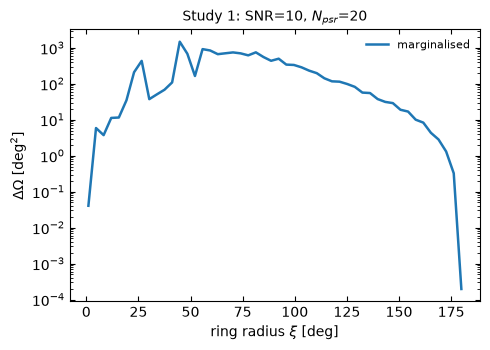

In [3]:
# Study 1: dOmega vs ring radius, distances effectively unknown (sigma_L = 1e40 kpc, as in the paper)
# wall clock, RTX 4090 incl. compile: 0.9 s
t = time.perf_counter()
xi1 = jnp.linspace(1.0, 179.9, 50)
dOm1 = jax.vmap(lambda x: ring(x, 1e40))(xi1).block_until_ready()
print(f"Study 1: {time.perf_counter() - t:.1f} s")
eu.plot_curves(xi1, {"marginalised": dOm1}, r"ring radius $\xi$ [deg]",
               title=f"Study 1: SNR={SNR_TARGET:g}, $N_{{psr}}$={N_PSR}");

**Exercise — open the Fisher machinery.** The cell below rebuilds one ΔΩ by hand on Steve's Study 0 ring.

**Your task:** read the cell and the helper it reproduces (`eu.ring_dOmega` → `urf.calibrated_fisher` → `urf.compute_sky_area`). `eu.fisher_matrix` and the Schur step are what Sections 2 and 3 call directly.

In [4]:
# Steve's Study 0 ring: xi = 80 deg, 10 pulsars, source at phi = pi/2, sigma_L = 100 lambda_GW.
XI0, N0, SIG0 = 80.0, 10, 100 * LAMBDA_KPC
b8 = BASE8.at[1].set(jnp.pi / 2)
b0 = eu.ring_batch(XI0, N0, TOAS, TOAERRS, L0, SIG0, b8[0], b8[1])
circ = lambda p, b: uvf.get_delay_batch(p, b, True, False, TREF)          # Steve's circular model, pulsar term linked
p0 = eu.calibrate_log10_dL(circ, jnp.concatenate([b8, jnp.zeros(N0)]), b0.toaerrs, SNR_TARGET, idx=5, args=(b0,))
# all 8 CW params free, plus the N0 normalised pulsar distances (unit prior) that ring_dOmega also carries
F = eu.fisher_matrix(circ, p0, b0.toaerrs, tuple(range(8 + N0)), jnp.concatenate([jnp.zeros(8), jnp.ones(N0)]), args=(b0,))
# raw cond mixes parameter units; print_cond (Sections 2-3) reports the diagonally scaled one, which the 1e12/1e14 limits refer to
print(f"F shape {F.shape}, jnp.linalg.cond(F) = {float(jnp.linalg.cond(F)):.2e}, scaled = {eu.scaled_cond(F):.2e}")

A = F[:2, :2]                                      # sky block: indices 0, 1 = (cos theta, phi)
B = F[2:, :2]                                      # nuisance-sky coupling
C = F[2:, 2:]                                      # nuisance block
F_sky = A - B.T @ jnp.linalg.solve(C, B)           # Schur complement = Fisher of the sky, marginalised over the rest
dOm0 = (180 / jnp.pi)**2 * 2 * jnp.pi / jnp.sqrt(jnp.linalg.det(F_sky))   # 2 pi sqrt(det Cov_sky) [deg^2]
ref0 = eu.ring_dOmega(XI0, SIG0, b8, TOAS, TOAERRS, TREF, L0, SNR_TARGET, n_psr=N0)
print(f"dOmega: Schur by hand {float(dOm0):.8g}, eu.ring_dOmega {float(ref0):.8g} deg^2")
assert abs(float(dOm0 / ref0) - 1) < 1e-6        # round-off floor ~ scaled cond x 1e-16 ~ 1e-6

F shape (18, 18), jnp.linalg.cond(F) = 2.79e+16, scaled = 6.78e+09


dOmega: Schur by hand 26.251075, eu.ring_dOmega 26.251075 deg^2


Study 3: 7.8 s   max dOm_D/dOm_L = 5.124e+06


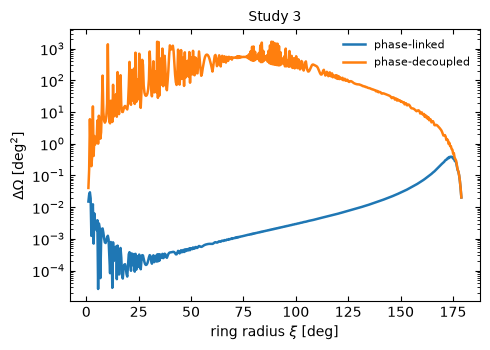

In [5]:
# Study 3: linked vs decoupled pulsar-term phase, same ring, sigma_L = SIGMA_L
# wall clock, RTX 4090 incl. compile: 7.7 s (Steve's notebook: 457 s)
t = time.perf_counter()
xi3 = jnp.linspace(1.0, 179.0, 500)
dOm3L = jax.vmap(lambda x: ring(x, SIGMA_L))(xi3).block_until_ready()
dOm3D = jax.vmap(lambda x: ring(x, SIGMA_L, True))(xi3).block_until_ready()
print(f"Study 3: {time.perf_counter() - t:.1f} s   max dOm_D/dOm_L = {float((dOm3D / dOm3L).max()):.3e}")
eu.plot_curves(xi3, {"phase-linked": dOm3L, "phase-decoupled": dOm3D}, r"ring radius $\xi$ [deg]", title="Study 3");

Study 4: 0.9 s   dOm(10)/dOm(50) at smallest sigma_L = 23.790


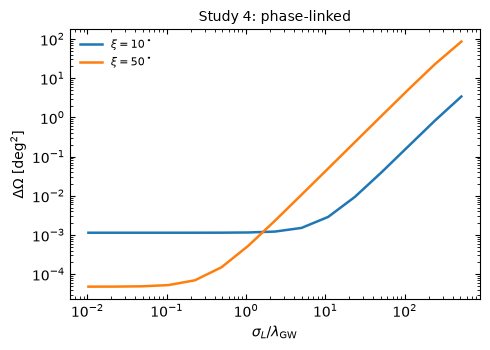

In [6]:
# Study 4: dOmega vs sigma_L, linked regime, xi = RING_RADIUS and 50 deg
# wall clock, RTX 4090 incl. compile: 0.9 s
t = time.perf_counter()
sig4 = SIG_OVER_LAM * LAMBDA_KPC
dOm4 = {xi: jax.vmap(lambda s: ring(xi, s))(sig4).block_until_ready() for xi in (RING_RADIUS, 50.0)}
print(f"Study 4: {time.perf_counter() - t:.1f} s   dOm({RING_RADIUS:g})/dOm(50) at smallest sigma_L = {float(dOm4[RING_RADIUS][0] / dOm4[50.0][0]):.3f}")
eu.plot_curves(SIG_OVER_LAM, {rf"$\xi={xi:g}^\circ$": v for xi, v in dOm4.items()},
               r"$\sigma_L/\lambda_{\rm GW}$", logx=True, title="Study 4: phase-linked");

**Compare with Steve's figures.** `outputs_fixed/` is not in the git clone; it is written when you run `../ring_pterm_vectorized_fixed.ipynb`. Copies of that notebook's saved figures are in `reference_figs/`.

| study | Steve's file | copy here |
|---|---|---|
| 1 | not saved by Steve; same curve as σ_L/λ = 1000 in `outputs_fixed/study1a_distance_uncertainty.pdf` | `reference_figs/study1_steve.png` |
| 3 | `outputs_fixed/study3_linked_v_decoupled.pdf` | `reference_figs/study3_steve.png` |
| 4 | `outputs_fixed/study4_distance_linked.pdf` (x in kpc; top axis σ_L/λ) | `reference_figs/study4_steve.png` |

## Section 2 — Eccentric Earth term, decoupled regime: ΔΩ(e) at fixed SNR

**What this does:**
- Replaces Steve's circular Earth term with your eccentric one (Peters–Mathews harmonics n ≤ `N_MAX`). **Pulsar term OFF** — Earth term only.
- At each e the amplitude (log₁₀ d_L) is rescaled so the SNR summed over harmonics and pulsars equals the target; Fisher by `jax.jacfwd`; sky marginalised with Steve's Schur helper.
- Hidden dependency: Steve's circular model evolves the frequency across the 10-yr span. Leaving that out changes the residual by 5.7e-3 of its peak, more than the 1e-3 validation tolerance. So your eccentric Earth term must evolve (f_orb, e) over the observation too.

**Conventions:**
- Phase: at e→0 the orbital phase is l + ω, so `ecc_from_circular` sets l₀ = phase0/2 − ω (ω plays the role of Taylor+2016's γ).
- Frequency: log₁₀ f_orb is the **azimuthal** (observed) orbital frequency, 2π f_orb = n + ω̇ with n = dl/dt the mean motion. At e→0 the quadrupole then sits at exactly f_GW = 2 f_orb, so the check against Steve's circular model holds. Harmonic k has lines at k f_orb − (k−2) ω̇/2π [sin(kl+2ω)], k f_orb − (k+2) ω̇/2π [sin(kl−2ω)] and k f_orb − k ω̇/2π [the sin²ι part]. ω̇/(2π f_orb) = 3.2 % here, so a mean-motion reading fails the 1e-3 check for a reason unrelated to the waveform.
- The harmonic sum you need is for the timing **residual** (integrated strain, Taylor+2016 §4 eqs. 21–22), not for h₊,ₓ.

Parameter vector (`eu.ECC_PARAMS`; sky first because the Schur helper takes indices 0, 1 as the sky):

| # | parameter | Fisher? | fiducial |
|---|---|---|---|
| 0 | cos θ (sky) | yes | 0.01 |
| 1 | φ (sky) | yes | 0 |
| 2 | cos ι | yes | 0.99 |
| 3 | ψ | yes | 0 |
| 4 | log₁₀ f_orb | yes | log₁₀(f_GW/2) |
| 5 | e | yes (fixed in the e→0 check) | swept |
| 6 | ω, argument of periastron | yes (fixed in the e→0 check) | π/4 |
| 7 | l₀, mean anomaly at tref | yes | phase0/2 − ω |
| 8 | log₁₀ d_L | yes | set by SNR rescaling |
| 9 | log₁₀ M_c | yes | 9.5 |
| — | q, mass ratio | **held fixed** | 1 (M_tot = 4^{3/5} M_c); enters only through ω̇ — Peters f and e evolution depends on M_c alone |

Held fixed (not parameters): q = 1, `N_MAX`, `tref`, pulsar positions, TOAs, noise. ω is undefined at e = 0, so the e→0 check holds e and ω fixed.

**Your task:**
1. Implement `evolve_back_peters` (needed here and in Section 3).
2. Implement `ecc_residual_earth` using it.
3. Pass the validation cell; run the sweep.

**How you'll know it's right:** validation passes; at e→0 (e, ω fixed) ΔΩ matches the circular Earth-term reference printed below to < 1 %; condition numbers stay below ~1e12.

In [7]:
N_MAX    = 30                                   # harmonics in the sweep (static under jit). Convergence: rerun at 45, dOmega should move < 1%
OMEGA0   = jnp.pi / 4                           # fiducial argument of periastron [rad]
E_GRID   = np.arange(0.01, 0.70 + 1e-9, 0.05)   # 0.01, 0.06, ..., 0.66
SNR_LIST = (8.0, 10.0, 20.0)
SEC2_FREE = tuple(range(eu.N_GLOBAL))                                                # all 10 are Fisher parameters
CIRC_FREE = tuple(i for i in SEC2_FREE if i not in (eu.IDX["e"], eu.IDX["omega"]))  # e -> 0 check: e, omega fixed
P0 = eu.ecc_from_circular(BASE8, e=0.0, omega=OMEGA0)
batch2 = eu.ring_batch(RING_RADIUS, N_PSR, TOAS, TOAERRS, L0, SIGMA_L, BASE8[0], BASE8[1])  # positions only: pulsar term OFF
for name, v in zip(eu.ECC_PARAMS, P0):
    print(f"{name:>11s} = {float(v): .4f}")

# e -> 0 target: Steve's circular Earth term (pterm=False), same ring, same SNR, all 8 circular params free.
# (Section 1's decoupled value is not the target: it keeps the pulsar terms and their distance/phase nuisances.)
earth_circ = lambda p, b: uvf.get_delay_batch(p, b, False, False, TREF)
REF2 = {}
for s in SNR_LIST:
    p8 = eu.calibrate_log10_dL(earth_circ, BASE8, batch2.toaerrs, s, idx=5, args=(batch2,))
    REF2[s] = float(urf.compute_sky_area_schur(eu.fisher_matrix(earth_circ, p8, batch2.toaerrs, tuple(range(8)), args=(batch2,))))
print("circular Earth-term dOmega [deg^2]:", {s: f"{v:.3g}" for s, v in REF2.items()})
print(f"for contrast, Section 1 decoupled (pulsar term on) at xi={RING_RADIUS:g}: {float(ring(RING_RADIUS, SIGMA_L, True)):.3g} deg^2")

  cos_theta =  0.0100
        phi =  0.0000
    cos_inc =  0.9900
        psi =  0.0000
 log10_forb = -8.3010
          e =  0.0000
      omega =  0.7854
         l0 = -0.7854
   log10_dL =  2.3850
   log10_Mc =  9.5000


circular Earth-term dOmega [deg^2]: {8.0: '5.01', 10.0: '3.21', 20.0: '0.802'}


for contrast, Section 1 decoupled (pulsar term on) at xi=10: 24 deg^2


In [ ]:
# Validation: e = 1e-4, n_max = 2 must match Steve's circular Earth term.
# Tolerance 1e-3 of the peak residual. Genuine O(e) differences (n=1 harmonic kept, n=3 dropped) are
# a few x e ~ few x 1e-4. Leaving out the 10-yr frequency evolution costs 5.7e-3; a factor-2 f_orb/f_GW
# slip, a sign flip or a phase-convention mismatch cost O(1). All of those fail. So does reading
# log10_forb as the mean motion: with omegadot on, the quadrupole moves by omegadot/(2 pi f_orb) = 3.2%.
p_val = eu.ecc_from_circular(BASE8, e=1e-4, omega=0.0)
r_ecc = eu.ecc_residual_earth(p_val, batch2.toas, batch2.pos, 2, TREF)
r_circ = uvf.get_delay_batch(BASE8, batch2, False, False, TREF)
err = float(jnp.max(jnp.abs(r_ecc - r_circ)) / jnp.max(jnp.abs(r_circ)))
print(f"max|r_ecc - r_circ| / max|r_circ| = {err:.2e}   (tolerance 1e-3)")
assert err < 1e-3, "eccentric Earth term does not reduce to Steve's circular waveform"

In [ ]:
# Sweep: dOmega(e) at fixed SNR. PULSAR TERM OFF (Earth term only).
earth_ecc = lambda p, b: eu.ecc_residual_earth(p, b.toas, b.pos, N_MAX, TREF)

# e -> 0 check (e, omega fixed) against the circular reference
p = eu.calibrate_log10_dL(earth_ecc, P0.at[eu.IDX["e"]].set(1e-4), batch2.toaerrs, 10.0, args=(batch2,))
d0 = float(urf.compute_sky_area_schur(eu.fisher_matrix(earth_ecc, p, batch2.toaerrs, CIRC_FREE, args=(batch2,))))
print(f"e->0: {d0:.4g} vs circular {REF2[10.0]:.4g} deg^2  (ratio {d0 / REF2[10.0]:.4f}, want 1 +- 0.01)")

# If cond > 1e12 only at the smallest e, suspect omega-l0 near-degeneracy (they enter as omega + l at O(e^0)).
dOm2, cond2 = {}, {}
for s in SNR_LIST:
    dOm2[s], cond2[s] = [], []
    for e in E_GRID:
        p = eu.calibrate_log10_dL(earth_ecc, P0.at[eu.IDX["e"]].set(e), batch2.toaerrs, s, args=(batch2,))
        F = eu.fisher_matrix(earth_ecc, p, batch2.toaerrs, SEC2_FREE, args=(batch2,))
        cond2[s].append(eu.print_cond(f"SNR={s:g} e={e:.2f}", F))
        dOm2[s].append(float(urf.compute_sky_area_schur(F)))
eu.plot_curves(E_GRID, {f"SNR={s:g}": dOm2[s] for s in SNR_LIST}, "e",
               hline=(REF2[10.0], "circular, SNR=10"), title="Section 2: Earth term only");

**What to look for** (one sentence each):
1. Does ΔΩ at fixed SNR depend on e, and by how much across the grid?
2. Does ΔΩ scale as SNR⁻²? If not, why not?
3. Rerun with `N_MAX = 45`: does any point move by more than 1 %?

## Section 3 — Evolved pulsar terms, linked regime: σ_L sweep at a few e

**What this does:** puts the pulsar term back. Pulsar i sees the binary earlier by dt_i = L_i (1 − cos ξ_i)/c. At that epoch the linked pulsar term needs:
- f_p — Peters, from `evolve_back_peters`;
- e_p — Peters, from `evolve_back_peters`;
- ω_p — 1PN periastron advance (q = 1), integrated alongside f and e in `evolve_back_peters`;
- the mean anomaly l_p = l₀ − ∫ (2π f_orb − ω̇) dt over the lag, with f_orb and e evolving under the integral. Under the azimuthal convention dl/dt = 2π f_orb − ω̇; integrating 2π f_orb alone while also evolving ω counts the advance twice. `evolve_back_peters` returns only (f_p, e_p, ω_p), so compute this phase integral inside `ecc_residual_full` (or a helper you add).

Why precession is in: at the fiducial source (M_tot = 7.27×10⁹ M☉), ω̇·dt ≈ 1.6 rad at ξ = 10°, ≈ 36 rad at ξ = 50° (L = 1 kpc), and ≈ 0.3 rad over the 10-yr Earth term.

Runs the Study 4 σ_L grid at SNR = 10 for e ∈ {0, 0.2, 0.4, 0.6}. Fisher parameters: the 10 globals + N normalised pulsar distances with unit prior (Steve's convention, L_i = L0 + σ_L θ_i). At e = 0, e and ω are held fixed — that curve must equal Study 4.

**Your task:** implement `evolve_back_peters` and `ecc_residual_full`; pass checks (a), (b), (c); run the sweep.

**How you'll know it's right:** (a), (b), (c) pass; no Fisher matrix is flagged (cond > 1e14).

**What to look for** (one sentence each):
1. Do the e > 0 curves reach the plateau at a looser σ_L than e = 0?
2. Does the plateau itself sit lower?

In [ ]:
# (a) evolve_back_peters at e = 0 vs Steve's circular omega_p0.
# Steve exposes omega_p0 only through the linked pulsar phase it implies
# (compute_pulsar_phases_batch: pphase = (w0^-5/3 - omega_p0^-5/3) / (32 Mc^5/3)); inverted here.
# Tolerance 1e-6 on the frequency shift f_orb - f_orb_p (shift ~ 3e-3 f_orb at 10 deg): the closed form
# is exact, and a sensible ODE solve beats 1e-6 easily.
batch3 = eu.ring_batch(RING_RADIUS, N_PSR, TOAS, TOAERRS, L0, SIGMA_L, BASE8[0], BASE8[1])
pv = jnp.concatenate([BASE8, jnp.zeros(N_PSR)])          # normalised distances 0 -> L_i = L0
mc_s, w0 = 10**LOG10_MC * const.Tsun, jnp.pi * 10**LOG10_FGW
f_ref = (w0**(-5/3) - 32 * mc_s**(5/3) * uvf.compute_pulsar_phases_batch(pv, batch3, tref=TREF))**(-3/5) / (2 * jnp.pi)
_, _, cos_xi = uvf.create_gw_antenna_pattern_vmap(batch3.pos, jnp.arccos(BASE8[0]), BASE8[1])
dt = L0 * const.kpc / const.c * (1 - cos_xi)
f0 = 10**LOG10_FGW / 2
f_p, e_p, om_p = jax.vmap(eu.evolve_back_peters, in_axes=(None, None, None, None, 0))(f0, 0.0, OMEGA0, 10**LOG10_MC, dt)
err = float(jnp.max(jnp.abs((f0 - f_p) - (f0 - f_ref)) / jnp.abs(f0 - f_ref)))
print(f"relative error on frequency shift = {err:.2e}  (tolerance 1e-6);  max e_p = {float(jnp.max(jnp.abs(e_p))):.1e}")
assert err < 1e-6 and float(jnp.max(jnp.abs(e_p))) < 1e-12

# omega: closed-form 1PN advance at e = 0 with f held at f0 (q = 1): omega_p - omega = -omegadot(f0) * dt.
# Tolerance 0.1 catches a wrong M_tot (x1.74), a sign flip or a factor 2. It is deliberately loose: omegadot may
# be written with 2 pi f_orb or with the mean motion n (a 2PN-order difference, ~5% here), and the exact integral
# differs from the fixed-f closed form by only 0.24% here, so a tighter bound would test convention, not correctness.
M_tot_s = 4**(3/5) * 10**LOG10_MC * const.Tsun                 # G M_tot / c^3 [s], q = 1
wdot0 = 3 * (2 * jnp.pi * f0)**(5/3) * M_tot_s**(2/3)          # [rad/s] at e = 0
tol_w = 0.1
err_w = float(jnp.max(jnp.abs((om_p - OMEGA0) / (-wdot0 * dt) - 1)))
print(f"omegadot*dt = {float(wdot0 * dt[0]):.3f} rad;  relative error vs fixed-f closed form = {err_w:.2e}  (tolerance {tol_w:.2e})")
assert err_w < tol_w

In [ ]:
# (b) full residual at e = 1e-4 vs get_delay_batch with the pulsar term on (linked), L_i = L0.
# Same 1e-3 tolerance and reasoning as the Section 2 check. Precession does not loosen it: with the azimuthal
# convention the circular-limit phase l + omega advances at exactly 2 pi f_orb, both at Earth and over the lag,
# so it tracks Steve's chirp phase. A wrong convention fails here, by design: a mean-motion f_orb (3.2% off
# in frequency), or l_p = l0 - int 2 pi f dt with omega also evolved (pulsar term ~1.6 rad off at 10 deg).
r_ecc = eu.ecc_residual_full(eu.ecc_from_circular(BASE8, e=1e-4), batch3.toas, batch3.pos,
                             jnp.full(N_PSR, L0), 2, TREF, linked=True)
r_circ = uvf.get_delay_batch(pv, batch3, True, False, TREF)
err = float(jnp.max(jnp.abs(r_ecc - r_circ)) / jnp.max(jnp.abs(r_circ)))
print(f"max|r_ecc - r_circ| / max|r_circ| = {err:.2e}   (tolerance 1e-3)")
assert err < 1e-3, "linked eccentric residual does not reduce to Steve's circular pulsar-term model"

In [ ]:
# (c) linked sigma_L sweep machinery; at e = 0 (e, omega fixed) it must reproduce Study 4 at xi = RING_RADIUS.
# Tolerance 1%: exact in exact arithmetic; an ODE-based back-evolution may shift dOmega slightly,
# a wrong linked phase changes it by orders of magnitude.
SEC3_SNR = 10.0

def full_resid(theta, b, sigma_L):               # theta = [10 globals, N normalised distances]
    return eu.ecc_residual_full(theta[:eu.N_GLOBAL], b.toas, b.pos, L0 + sigma_L * theta[eu.N_GLOBAL:],
                                N_MAX, TREF, linked=True)

def sec3_dOmega(e, sigma_L, free):
    b = eu.ring_batch(RING_RADIUS, N_PSR, TOAS, TOAERRS, L0, sigma_L, BASE8[0], BASE8[1])
    theta = jnp.concatenate([eu.ecc_from_circular(BASE8, e=e, omega=OMEGA0), jnp.zeros(N_PSR)])
    theta = eu.calibrate_log10_dL(full_resid, theta, b.toaerrs, SEC3_SNR, args=(b, sigma_L))
    free_all = free + tuple(range(eu.N_GLOBAL, eu.N_GLOBAL + N_PSR))
    prior = jnp.concatenate([jnp.zeros(len(free)), jnp.ones(N_PSR)])
    F = eu.fisher_matrix(full_resid, theta, b.toaerrs, free_all, prior, args=(b, sigma_L))
    return float(urf.compute_sky_area_schur(F)), F

dOm3_e0 = np.array([sec3_dOmega(0.0, s, CIRC_FREE)[0] for s in sig4])
worst = float(np.max(np.abs(dOm3_e0 / np.asarray(dOm4[RING_RADIUS]) - 1)))
print(f"max |dOmega_ecc(e=0) / dOmega_Study4 - 1| = {worst:.2e}  (tolerance 1e-2)")
assert worst < 1e-2, "e = 0 linked sweep does not reproduce Study 4"

In [ ]:
# Sweep: linked regime, SNR = 10, Study 4 sigma_L grid, e in {0, 0.2, 0.4, 0.6}.
# e = 0 uses CIRC_FREE (omega undefined) and is the curve validated in (c).
E3 = (0.0, 0.2, 0.4, 0.6)
dOm3e = {}
for e in E3:
    free = CIRC_FREE if e == 0 else SEC2_FREE
    dOm3e[e] = []
    for s in sig4:
        a, F = sec3_dOmega(e, s, free)
        eu.print_cond(f"e={e:.1f} sigma_L/lam={s / LAMBDA_KPC:.3g}", F, flag=1e14)
        dOm3e[e].append(a)
eu.plot_curves(SIG_OVER_LAM, {f"e={e:.1f}": v for e, v in dOm3e.items()}, r"$\sigma_L/\lambda_{\rm GW}$", logx=True,
               hline=(float(dOm4[RING_RADIUS].min()), r"circular floor (Study 4, $\sigma_L\to0$)"),
               title=rf"Section 3: linked, $\xi={RING_RADIUS:g}^\circ$, SNR=10");

## Extensions (in order)

a. **Free mass ratio.** Add log₁₀ M_tot (or η) as an 11th global parameter with a broad prior (the `prior` vector passed to `eu.fisher_matrix`, as for the pulsar distances), rerun the Section 3 sweep, and compare with the q = 1 curve. This corresponds to a real search, where q cannot be fixed. It needs: one more entry in `ECC_PARAMS` and `IDX`, its prior entry, and passing M_tot into `evolve_back_peters` instead of deriving it from M_c and q.

b. **Decoupled sweep.** Repeat Section 3 with `linked=False` and per-pulsar nuisance phases added to θ (as Steve's Study 5). This needs new plumbing that the scaffold does not provide: N extra entries in θ (fiducial = the linked l_p), zeros for them in the prior vector, and their indices in the `free` tuple. This is what current searches would see, and it is the first thing a referee will ask for.

c. **Inclination.** Rerun Section 2 at cos ι = 0.5. 0.99 is near face-on, a special case for eccentric polarisation content.

d. **ω dependence.** Repeat the Section 2 sweep at ω = 0 and π/2, or average over ω.

## Log

Fill this in as you go — it is where the paper draft starts.

### Knob-table sentences (Section 1)

### Each check's printed number
- Section 1 Fisher exercise:
- Section 2 validation:
- Section 2 e→0 ratio:
- Section 3 (a):
- Section 3 (b):
- Section 3 (c):

### Section 2 findings

### Section 3 findings

### Open questions